In [1]:
import tarfile
import os
import numpy as np
from tqdm import tqdm
from io import BytesIO
import matplotlib.pyplot as plt


In [ ]:

tar_path_1 = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_dxtb_all_modes/results_tmqm_fock.tar'
tar_path_2 = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_dxtb_all_modes/results_tmqm_charge.tar'
tar_path_3 = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_dxtb_all_modes/results_tmqm_potential.tar'

with tarfile.open(tar_path_1, 'r') as tar1, tarfile.open(tar_path_2, 'r') as tar2, tarfile.open(tar_path_3, 'r') as tar3, tarfile.open('filtered_results_tmqm.tar', 'w') as out_tar:
    members1 = tar1.getnames()
    members2 = tar2.getnames()
    members3 = tar3.getnames()
    
    basenames1 = [os.path.basename(m) for m in members1]
    basenames2 = [os.path.basename(m) for m in members2]
    basenames3 = [os.path.basename(m) for m in members3]
    
    basenames1 = [b for b in basenames1 if b.endswith('.npz')]
    basenames2 = [b for b in basenames2 if b.endswith('.npz')]
    basenames3 = [b for b in basenames3 if b.endswith('.npz')]
    
    basenames1 = [b for b in basenames1 if not 'dsgdb9nsd' in b]
    basenames2 = [b for b in basenames2 if not 'dsgdb9nsd' in b]
    basenames3 = [b for b in basenames3 if not 'dsgdb9nsd' in b]
    
    basenames1 = [b for b in basenames1 if not '-' in b]
    basenames2 = [b for b in basenames2 if not '-' in b]
    basenames3 = [b for b in basenames3 if not '-' in b]

    common_files = set(basenames1) & set(basenames2) & set(basenames3)
    print(f"Common files: {len(common_files)}")
    for filename in tqdm(common_files):
        if '-' in filename or 'dsgdb9nsd' in filename:
            continue
        file1 = tar1.extractfile('results_tmqm_fock/'+filename)
        file2 = tar2.extractfile('results_tmqm_charge/'+filename)
        file3 = tar3.extractfile('results_tmqm_potential/'+filename)
        
        if file1 is not None and file2 is not None:
            data1 = file1.read()
            data2 = file2.read()
            data3 = file3.read()
            
            data1 = np.load(BytesIO(data1))
            data2 = np.load(BytesIO(data2))
            data3 = np.load(BytesIO(data3))
            close12 = np.allclose(data1['final_charges'], data2['final_charges'], rtol=1e-2, atol=1e-2)
            close13 = np.allclose(data1['final_charges'], data3['final_charges'], rtol=1e-2, atol=1e-2)
            close23 = np.allclose(data2['final_charges'], data3['final_charges'], rtol=1e-2, atol=1e-2)
            n_scf_iter1 = data1['n_scf_iter']
            n_scf_iter2 = data2['n_scf_iter']
            n_scf_iter3 = data3['n_scf_iter']
            max_n_scf_iter = max(n_scf_iter1, n_scf_iter2, n_scf_iter3)
            if close12 and close13 and close23: # and max_n_scf_iter < 499
                tarinfo = tar3.getmember('results_tmqm_potential/' + filename)
                file3 = tar3.extractfile(tarinfo)
                tarinfo.name = filename  # flatten structure in output tar
                out_tar.addfile(tarinfo, fileobj=file3)
            else:
                continue
            
            
            

Common files: 70921


100%|██████████| 70921/70921 [06:40<00:00, 176.97it/s]


In [12]:
filtered_tar_path = '/home/ihor/projects/MLGuessQC/notebooks/filtered_results_tmqm.tar'
filtered_potential = []
filtered_charges = []
unique_numbers = []
n_scf_list = []
with tarfile.open(filtered_tar_path, 'r') as filtered_tar:
    filtered_members = filtered_tar.getnames()
    for member in tqdm(filtered_members):
        if member.endswith('.npz'):
            file = filtered_tar.extractfile(member)
            data = np.load(BytesIO(file.read()))
            filtered_potential.append(data['final_potential'])
            filtered_charges.append(data['final_charges'])
            unique_numbers.append(data['numbers'])
            n_scf_list.append(data['n_scf_iter'])

unique_numbers_counts = {}
for numbers in tqdm(unique_numbers):
    for num in numbers:
        if num not in unique_numbers_counts:
            unique_numbers_counts[num] = 0
        unique_numbers_counts[num] += 1
unique_numbers = set(np.concatenate(unique_numbers))

100%|██████████| 43597/43597 [00:00<00:00, 88029.61it/s] 


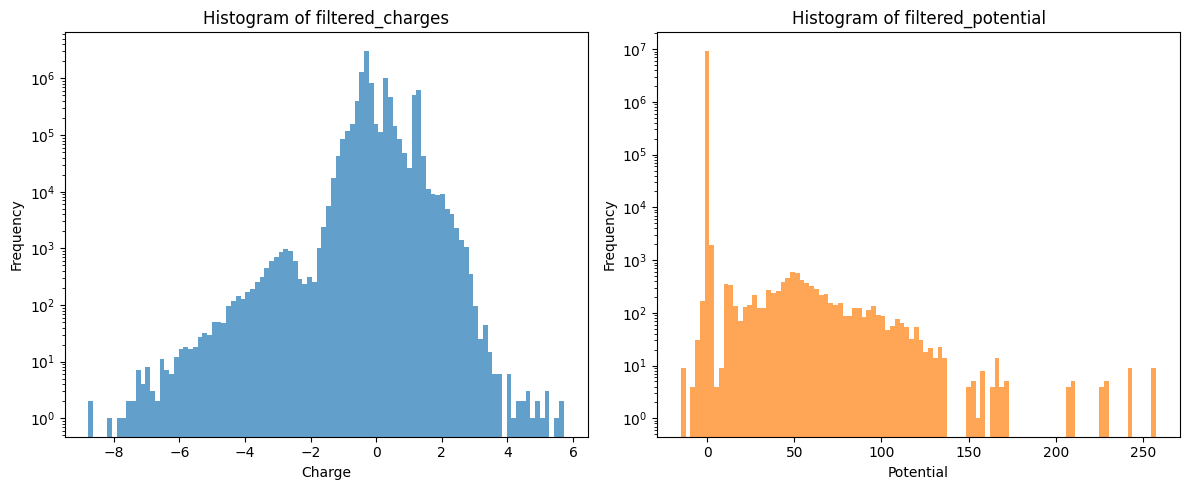

In [13]:

import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# Flatten the lists of arrays for histogram plotting
charges_flat = np.concatenate(filtered_charges)
potential_flat = np.concatenate(filtered_potential)

axs[0].hist(charges_flat, bins=100, color='tab:blue', alpha=0.7)
axs[0].set_title('Histogram of filtered_charges')
axs[0].set_xlabel('Charge')
axs[0].set_yscale('log')
axs[0].set_ylabel('Frequency')

axs[1].hist(potential_flat, bins=100, color='tab:orange', alpha=0.7)
axs[1].set_title('Histogram of filtered_potential')
axs[1].set_xlabel('Potential')
axs[1].set_ylabel('Frequency')
axs[1].set_yscale('log')

plt.tight_layout()
plt.show()

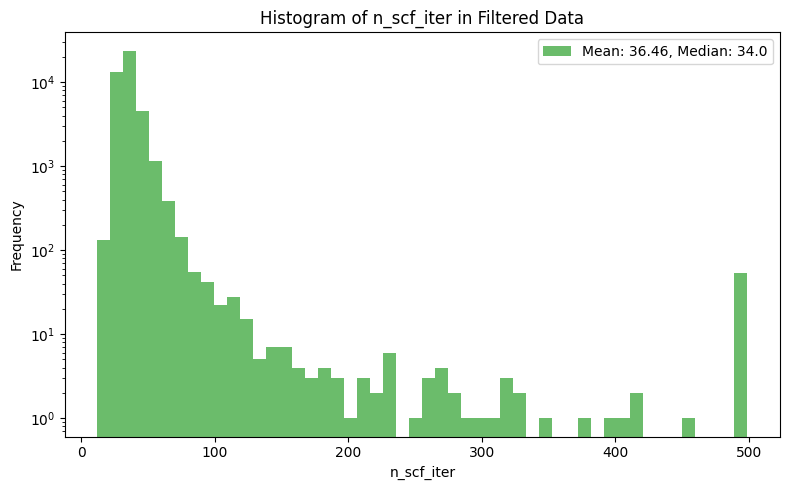

In [21]:
# Flatten n_scf_list and plot histogram
n_scf_flat = np.concatenate(n_scf_list)
plt.figure(figsize=(8, 5))
plt.hist(n_scf_flat, bins=50, color='tab:green', alpha=0.7, label="Mean: {:.2f}, Median: {:.1f}".format(np.mean(n_scf_flat), np.median(n_scf_flat)))
plt.xlabel('n_scf_iter')
plt.ylabel('Frequency')
plt.title('Histogram of n_scf_iter in Filtered Data')
plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

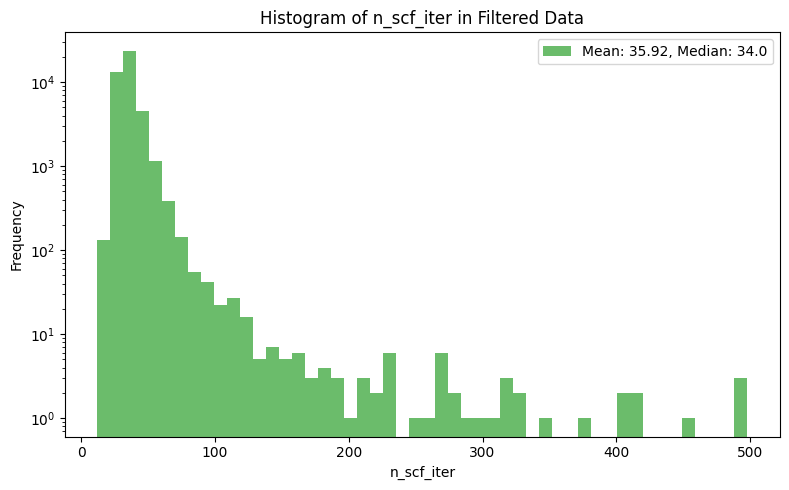

In [28]:
# Flatten n_scf_list and plot histogram
n_scf_flat = np.concatenate(n_scf_list)
n_scf_flat_converged = n_scf_flat[n_scf_flat < 499]  # Filter outliers if necessary
plt.figure(figsize=(8, 5))
plt.hist(n_scf_flat_converged, bins=50, color='tab:green', alpha=0.7, label="Mean: {:.2f}, Median: {:.1f}".format(np.mean(n_scf_flat_converged), np.median(n_scf_flat_converged)))
plt.xlabel('n_scf_iter')
plt.ylabel('Frequency')
plt.title('Histogram of n_scf_iter in Filtered Data')
plt.yscale('log')
plt.legend()
plt.tight_layout()
plt.show()

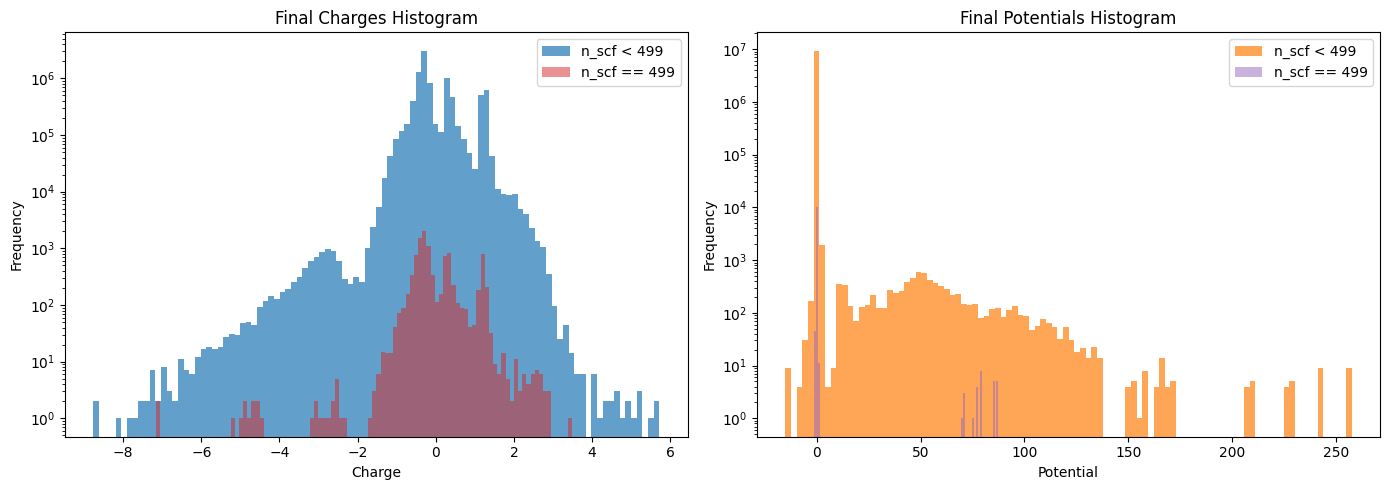

In [33]:
# Mask for converged and unconverged samples
converged_mask = np.array([arr[0] < 499 for arr in n_scf_list])
unconverged_mask = np.array([arr[0] == 499 for arr in n_scf_list])

# Flatten charges and potentials for each group
charges_converged = np.concatenate([filtered_charges[i] for i in range(len(filtered_charges)) if converged_mask[i]])
charges_unconverged = np.concatenate([filtered_charges[i] for i in range(len(filtered_charges)) if unconverged_mask[i]])
potential_converged = np.concatenate([filtered_potential[i] for i in range(len(filtered_potential)) if converged_mask[i]])
potential_unconverged = np.concatenate([filtered_potential[i] for i in range(len(filtered_potential)) if unconverged_mask[i]])

fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Charges histogram
axs[0].hist(charges_converged, bins=100, color='tab:blue', alpha=0.7, label='n_scf < 499')
axs[0].hist(charges_unconverged, bins=100, color='tab:red', alpha=0.5, label='n_scf == 499')
axs[0].set_title('Final Charges Histogram')
axs[0].set_xlabel('Charge')
axs[0].set_ylabel('Frequency')
axs[0].set_yscale('log')
axs[0].legend()

# Potentials histogram
axs[1].hist(potential_converged, bins=100, color='tab:orange', alpha=0.7, label='n_scf < 499')
axs[1].hist(potential_unconverged, bins=100, color='tab:purple', alpha=0.5, label='n_scf == 499')
axs[1].set_title('Final Potentials Histogram')
axs[1].set_xlabel('Potential')
axs[1].set_ylabel('Frequency')
axs[1].set_yscale('log')
axs[1].legend()

plt.tight_layout()
plt.show()

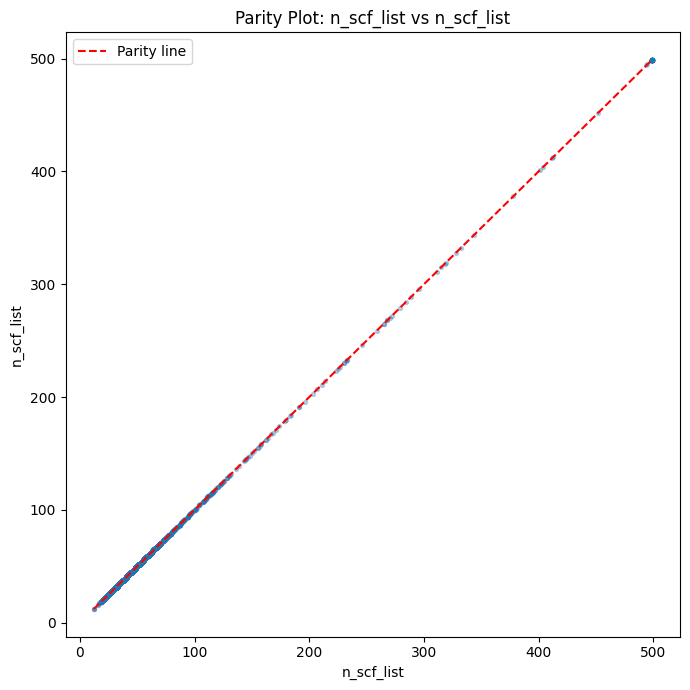

In [29]:
# Flatten n_scf_list for plotting
n_scf_flat = np.concatenate(n_scf_list)

plt.figure(figsize=(7, 7))
plt.scatter(n_scf_flat, n_scf_flat, alpha=0.3, s=8, color='tab:blue')
plt.plot([n_scf_flat.min(), n_scf_flat.max()],
         [n_scf_flat.min(), n_scf_flat.max()],
         'r--', label='Parity line')
plt.xlabel('n_scf_list')
plt.ylabel('n_scf_list')
plt.title('Parity Plot: n_scf_list vs n_scf_list')
plt.legend()
plt.tight_layout()
plt.show()

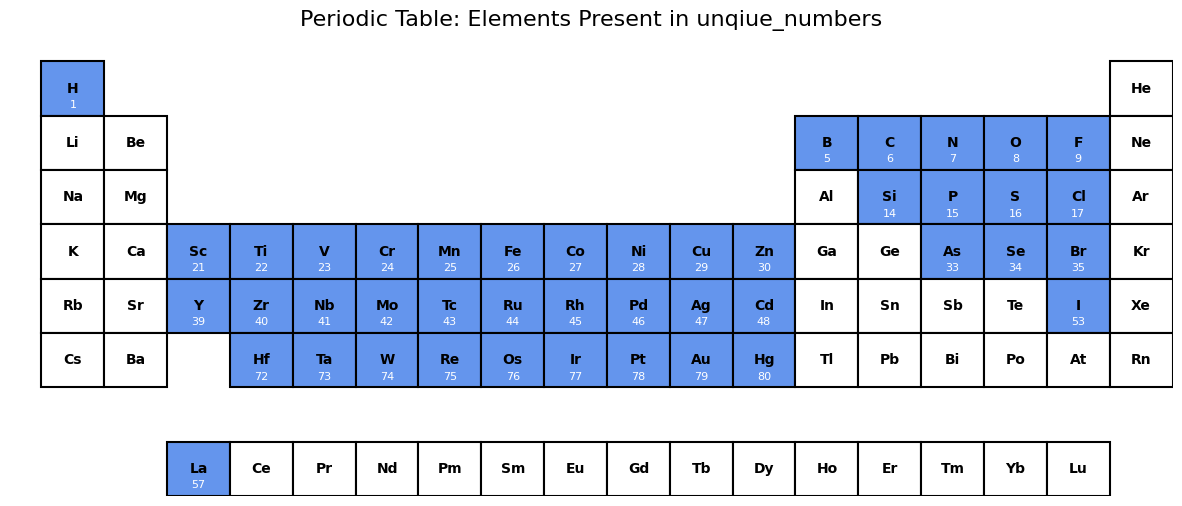

In [8]:
from matplotlib import colors

# Periodic table layout (row, col) for each atomic number (1-indexed)
periodic_table_layout = {
    1: (0, 0), 2: (0, 17),
    3: (1, 0), 4: (1, 1), 5: (1, 12), 6: (1, 13), 7: (1, 14), 8: (1, 15), 9: (1, 16), 10: (1, 17),
    11: (2, 0), 12: (2, 1), 13: (2, 12), 14: (2, 13), 15: (2, 14), 16: (2, 15), 17: (2, 16), 18: (2, 17),
    19: (3, 0), 20: (3, 1), 21: (3, 2), 22: (3, 3), 23: (3, 4), 24: (3, 5), 25: (3, 6), 26: (3, 7), 27: (3, 8), 28: (3, 9), 29: (3, 10), 30: (3, 11), 31: (3, 12), 32: (3, 13), 33: (3, 14), 34: (3, 15), 35: (3, 16), 36: (3, 17),
    37: (4, 0), 38: (4, 1), 39: (4, 2), 40: (4, 3), 41: (4, 4), 42: (4, 5), 43: (4, 6), 44: (4, 7), 45: (4, 8), 46: (4, 9), 47: (4, 10), 48: (4, 11), 49: (4, 12), 50: (4, 13), 51: (4, 14), 52: (4, 15), 53: (4, 16), 54: (4, 17),
    55: (5, 0), 56: (5, 1), 57: (7, 2), 58: (7, 3), 59: (7, 4), 60: (7, 5), 61: (7, 6), 62: (7, 7), 63: (7, 8), 64: (7, 9), 65: (7, 10), 66: (7, 11), 67: (7, 12), 68: (7, 13), 69: (7, 14), 70: (7, 15), 71: (7, 16),
    72: (5, 3), 73: (5, 4), 74: (5, 5), 75: (5, 6), 76: (5, 7), 77: (5, 8), 78: (5, 9), 79: (5, 10), 80: (5, 11), 81: (5, 12), 82: (5, 13), 83: (5, 14), 84: (5, 15), 85: (5, 16), 86: (5, 17),
}

# Element symbols for atomic numbers 1-86
element_symbols = [
    '', 'H', 'He',
    'Li', 'Be', 'B', 'C', 'N', 'O', 'F', 'Ne',
    'Na', 'Mg', 'Al', 'Si', 'P', 'S', 'Cl', 'Ar',
    'K', 'Ca', 'Sc', 'Ti', 'V', 'Cr', 'Mn', 'Fe', 'Co', 'Ni', 'Cu', 'Zn',
    'Ga', 'Ge', 'As', 'Se', 'Br', 'Kr',
    'Rb', 'Sr', 'Y', 'Zr', 'Nb', 'Mo', 'Tc', 'Ru', 'Rh', 'Pd', 'Ag', 'Cd',
    'In', 'Sn', 'Sb', 'Te', 'I', 'Xe',
    'Cs', 'Ba', 'La', 'Ce', 'Pr', 'Nd', 'Pm', 'Sm', 'Eu', 'Gd', 'Tb', 'Dy', 'Ho', 'Er', 'Tm', 'Yb', 'Lu',
    'Hf', 'Ta', 'W', 'Re', 'Os', 'Ir', 'Pt', 'Au', 'Hg', 'Tl', 'Pb', 'Bi', 'Po', 'At', 'Rn'
]

# Prepare data for plotting
counts = {num: 0 for num in range(1, 87)}
for n in unique_numbers:
    if n in counts:
        counts[n] = 1  # Mark present

# Plot
fig, ax = plt.subplots(figsize=(15, 6))
for num in range(1, 87):
    if num in periodic_table_layout:
        row, col = periodic_table_layout[num]
        present = counts[num]
        color = 'cornflowerblue' if present else 'white'
        rect = plt.Rectangle((col, -row), 1, -1, facecolor=color, edgecolor='k', lw=1.5)
        ax.add_patch(rect)
        ax.text(col + 0.5, -row - 0.5, element_symbols[num], ha='center', va='center', fontsize=10, fontweight='bold')
        if present:
            ax.text(col + 0.5, -row - 0.8, str(num), ha='center', va='center', fontsize=8, color='white')

ax.set_xlim(-0.5, 18)
ax.set_ylim(-8, 0.5)
ax.axis('off')
ax.set_title('Periodic Table: Elements Present in unqiue_numbers', fontsize=16)
plt.show()

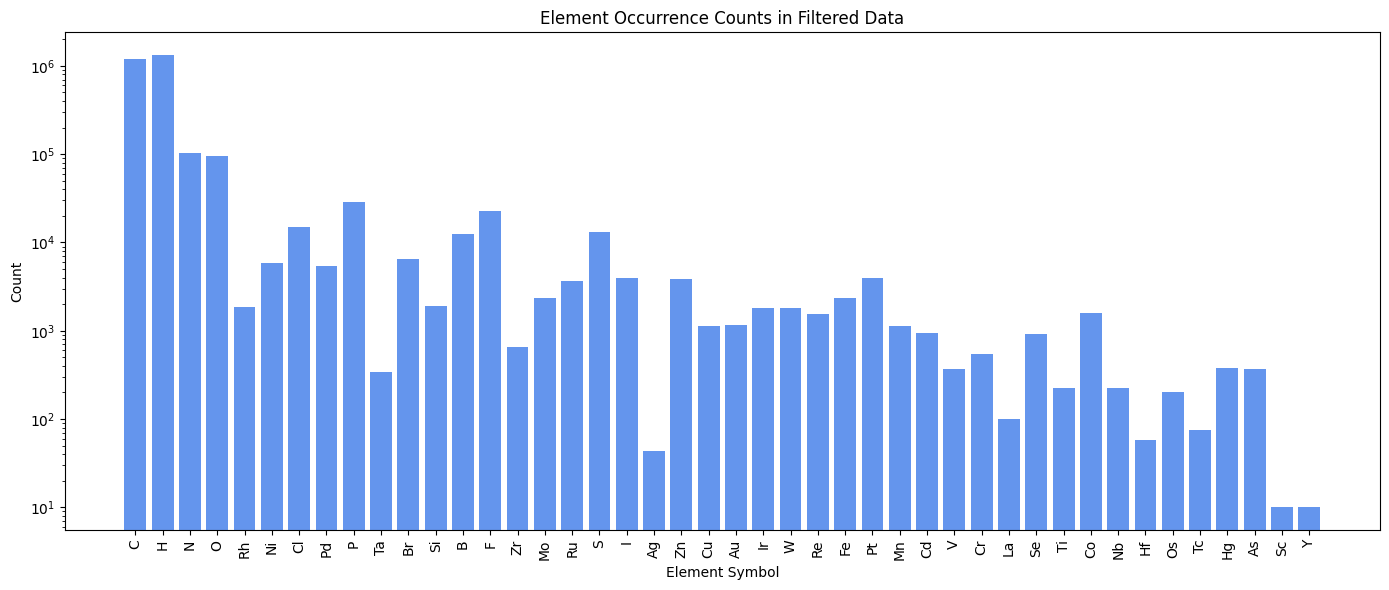

In [9]:
# Bar plot of unique_numbers_counts
plt.figure(figsize=(14, 6))
elements = [element_symbols[num] for num in unique_numbers_counts.keys()]
counts_vals = list(unique_numbers_counts.values())
plt.bar(elements, counts_vals, color='cornflowerblue')
plt.xlabel('Element Symbol')
plt.ylabel('Count')
plt.yscale('log')
plt.title('Element Occurrence Counts in Filtered Data')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [11]:
unique_numbers_counts[39]

10

# Filter out outliers

In [9]:
import pandas as pd

ids_to_remove_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/ids_to_remove.csv'
ids_to_remove = pd.read_csv(ids_to_remove_path)["id"].tolist()
print(f"Loaded {len(ids_to_remove)} IDs to remove.")

Loaded 189 IDs to remove.


In [10]:
tar_path = '/home/ihor/projects/MLGuessQC/datasets/tmQMneutral_FPCmatch_charges/filtered_results_tmqm.tar'

with tarfile.open(tar_path, 'r') as tar_original, tarfile.open('filtered_FPCmodes_outliers_tmqm.tar', 'w') as out_tar:
    members = tar_original.getnames()
    
    basenames = [os.path.basename(m) for m in members]
    basenames = [b for b in basenames if b.endswith('.npz')]
    print(f"Number of Files: {len(basenames)}")
    for filename in tqdm(basenames):
        if '-' in filename or 'dsgdb9nsd' in filename:
            continue
        if filename.split('_')[0] in ids_to_remove:
            continue
        tarinfo = tar_original.getmember(filename)
        file = tar_original.extractfile(tarinfo)
        tarinfo.name = filename  # flatten structure in output tar
        out_tar.addfile(tarinfo, fileobj=file)

Number of Files: 43597


100%|██████████| 43597/43597 [00:39<00:00, 1117.61it/s]


## Sanity check

In [13]:
with tarfile.open('/home/ihor/projects/MLGuessQC/notebooks/filtered_FPCmodes_outliers_tmqm.tar', 'r') as tar:
    members_filtered = tar.getnames()
    print(f"Number of members: {len(members_filtered)}")
    print("Expected: ", 43597 - 189)

Number of members: 43408
Expected:  43408
